# Rainfall Prediction Using Machine Learning
### CA3 – Predictive Analytics | KDD Process

**Objective:** Predict whether it will rain the next day (`RainTomorrow`) using historical Australian weather observations.



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Stage 1 — Business Understanding

Rainfall prediction can support agriculture, water management, and weather-related planning. This is a **binary classification** problem:

- `Yes` = rain tomorrow
- `No` = no rain tomorrow



## Stage 2 — Data Selection

Use the `weatherAUS.csv` dataset. The target column is `RainTomorrow`; `Date` is used to preserve chronological order. Upload the CSV file

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

df = pd.read_csv('/content/drive/MyDrive/Predictive Analysis/weatherAUS.csv')

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values in top 10 columns:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

Dataset shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No



Missing values in top 10 columns:


,0
Sunshine,69835
Evaporation,62790
Cloud3pm,59358
Cloud9am,55888
Pressure9am,15065
Pressure3pm,15028
WindDir9am,10566
WindGustDir,10326
WindGustSpeed,10263
Humidity3pm,4507


## Stage 3 — Data Understanding (EDA)

First, inspect how many records belong to each target class. This helps us see whether rain and no-rain observations are balanced.

RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64


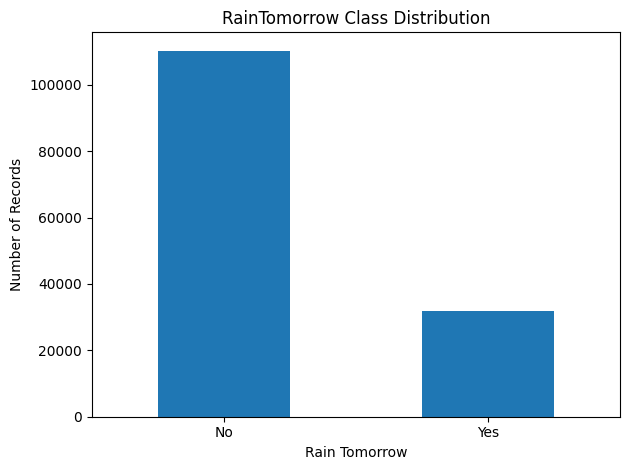

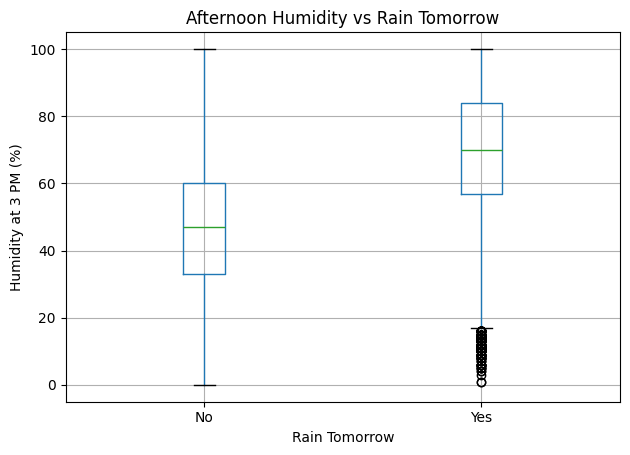

In [3]:
# Remove rows where the target is unknown
df = df.dropna(subset=['RainTomorrow']).copy()

print(df['RainTomorrow'].value_counts())
df['RainTomorrow'].value_counts().reindex(['No', 'Yes']).plot(
    kind='bar', title='RainTomorrow Class Distribution', xlabel='Rain Tomorrow', ylabel='Number of Records'
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# A simple relationship between afternoon humidity and next-day rain
if 'Humidity3pm' in df.columns:
    df.boxplot(column='Humidity3pm', by='RainTomorrow')
    plt.title('Afternoon Humidity vs Rain Tomorrow')
    plt.suptitle('')
    plt.xlabel('Rain Tomorrow')
    plt.ylabel('Humidity at 3 PM (%)')
    plt.tight_layout()
    plt.show()

## Stage 4 — Data Cleaning and Preprocessing

- Remove records where `RainTomorrow` is missing.
- Convert `Date` to a date format and sort records from oldest to newest.
- Fill missing numeric values using the median.

Preprocessing is fitted on the training data only to reduce data leakage.

## Stage 5 — Data Transformation / Feature Engineering

Extract `Month` and `Year` from `Date` to represent seasonal and yearly patterns. Convert the target to numeric labels (`No = 0`, `Yes = 1`). Keep the final 20% of chronological records as the test set.

In [4]:
# Parse dates, remove unusable dates, and sort chronologically
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date', 'RainTomorrow']).sort_values('Date').reset_index(drop=True)

# Feature engineering: month and year can represent seasonal patterns
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# Remove the target, raw date, and RISK_MM (next-day rainfall amount).
# RISK_MM can leak information about the target RainTomorrow.
X = df.drop(columns=['RainTomorrow', 'Date', 'RISK_MM'], errors='ignore')
y = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# Split by unique dates so observations from the same date do not appear
# in both training and testing sets.
unique_dates = df['Date'].drop_duplicates().sort_values().reset_index(drop=True)
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates.iloc[split_index]

train_mask = df['Date'] < split_date
test_mask = df['Date'] >= split_date

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

numeric_cols = X_train.select_dtypes(include=np.number).columns
categorical_cols = X_train.select_dtypes(exclude=np.number).columns

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Test period starts:", split_date.date())
print("Features used:", X.shape[1])

Training records: 109302
Testing records: 32891
Test period starts: 2015-08-08
Features used: 23


## Stage 6 — Data Mining (Model Building)

We will train and compare three approaches:

- **Dummy Classifier:** baseline that predicts the most frequent class.
- **Logistic Regression:** a simple, interpretable classification model that estimates the probability of rain.
- **Random Forest:** combines many decision trees and can learn more complex relationships.


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Preprocessing for Logistic Regression: scaling helps numeric features use comparable ranges
logistic_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

baseline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])

logistic_model = Pipeline([
    ('preprocessing', logistic_preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

random_forest = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train each model on the same training records
models = {
    'Baseline': baseline,
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

print("All three models trained successfully.")

All three models trained successfully.


## Stage 7 — Evaluation, Interpretation, and Conclusion

Compare all models on the same chronological test set using:

- **Accuracy:** proportion of all predictions that are correct.
- **Precision (Rain):** among predicted rainy days, how many were actually rainy.
- **Recall (Rain):** among actual rainy days, how many the model detected.
- **F1-score (Rain):** balance between precision and recall.

The following cells display a comparison table, classification report, and confusion matrices. The final cell then generates a written interpretation and conclusion using the actual computed metrics. Review these outputs before using them in your report.

**Important:** the model with the highest F1-score is selected for discussion, not automatically claimed to be universally best. Performance should be interpreted alongside false alarms, missed rainy days, and the baseline comparison.

,Model,Accuracy,Rain Precision,Rain Recall,Rain F1-score
1,Logistic Regression,0.795,0.523,0.736,0.612
2,Random Forest,0.847,0.767,0.437,0.557
0,Baseline,0.781,0.000,0.000,0.000


Classification report for best model by Rain F1-score: Logistic Regression
              precision    recall  f1-score   support

     No Rain       0.92      0.81      0.86     25680
        Rain       0.52      0.74      0.61      7211

    accuracy                           0.80     32891
   macro avg       0.72      0.77      0.74     32891
weighted avg       0.83      0.80      0.81     32891



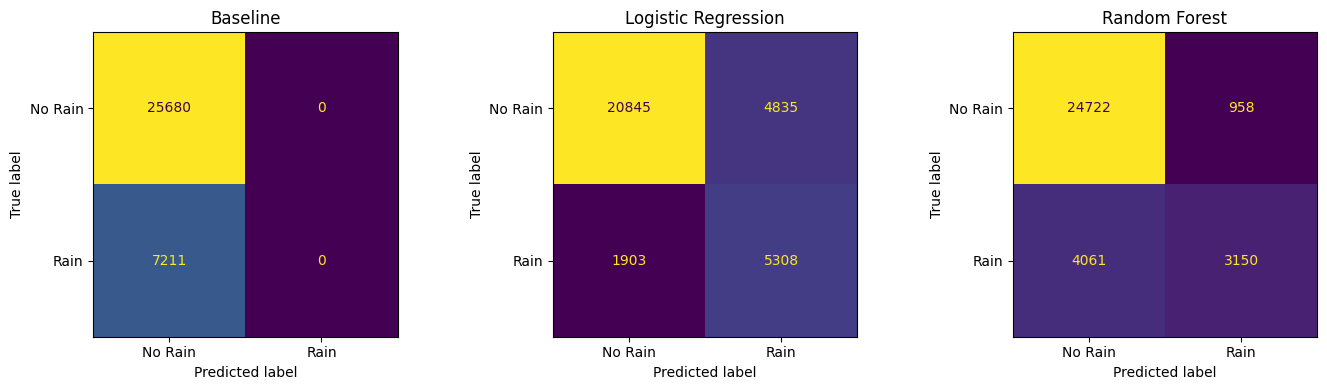

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Build a comparison table from the held-out test data
rows = []
for name, pred in predictions.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Rain Precision': precision_score(y_test, pred, zero_division=0),
        'Rain Recall': recall_score(y_test, pred, zero_division=0),
        'Rain F1-score': f1_score(y_test, pred, zero_division=0)
    })

results = pd.DataFrame(rows).sort_values('Rain F1-score', ascending=False)
display(results.round(3))

# Classification report for the best model by rain F1-score
best_name = results.iloc[0]['Model']
print(f"Classification report for best model by Rain F1-score: {best_name}")
print(classification_report(
    y_test, predictions[best_name],
    labels=[0, 1], target_names=['No Rain', 'Rain'], zero_division=0
))

# Confusion matrices make correct and incorrect predictions easier to explain
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred, labels=[0, 1]),
        display_labels=['No Rain', 'Rain']
    ).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Interpretation of Results and Conclusion


The conclusion is generated from the notebook's actual test results. Review the output and use it in the project report and individual presentation. The model is an educational exercise, not an operational weather-warning service.

In [8]:
# Short interpretation and conclusion
best_row = results.iloc[0]
best_name = best_row['Model']

print(f"Best model: {best_name}")
print(f"Accuracy: {best_row['Accuracy']:.3f} | "
      f"Rain Precision: {best_row['Rain Precision']:.3f} | "
      f"Rain Recall: {best_row['Rain Recall']:.3f} | "
      f"Rain F1-score: {best_row['Rain F1-score']:.3f}")

if best_name == 'Baseline':
    print("Conclusion: The baseline performed best on Rain F1-score. Improve features or model settings before relying on predictions.")
else:
    print(f"Conclusion: {best_name} achieved the highest Rain F1-score on this test period and is selected as the best model for this experiment.")

print("Note: This evaluation uses historical test data; it is not a live weather forecast.")

Best model: Logistic Regression
Accuracy: 0.795 | Rain Precision: 0.523 | Rain Recall: 0.736 | Rain F1-score: 0.612
Conclusion: Logistic Regression achieved the highest Rain F1-score on this test period and is selected as the best model for this experiment.
Note: This evaluation uses historical test data; it is not a live weather forecast.


In [11]:
# Select a location (example: 'Sydney', 'Melbourne', or 'Perth')
location_name = input("Enter a location from the dataset: ").strip()

if 'Location' not in df.columns:
    print("The dataset does not contain a Location column.")
else:
    location_rows = df[df['Location'].astype(str).str.lower() == location_name.lower()].copy()

    if location_rows.empty:
        print("Location not found. Check the spelling and try a location listed in df['Location'].unique().")
    else:
        # Use the most recent weather observation available for this location
        latest_row = location_rows.sort_values('Date').iloc[[-1]]
        latest_date = latest_row['Date'].iloc[0]

        # Build input using exactly the features used during model training
        latest_X = latest_row.reindex(columns=list(X.columns))
        predicted_label = models[best_name].predict(latest_X)[0]
        prediction = "YES — rain is predicted" if int(predicted_label) == 1 else "NO — rain is not predicted"

        print(f"Selected location: {location_name.title()}")
        print(f"Latest observation in dataset: {latest_date.date()}")
        print(f"Prediction for the following day: {prediction}")

Enter a location from the dataset: Sydney
Selected location: Sydney
Latest observation in dataset: 2017-06-25
Prediction for the following day: NO — rain is not predicted
